# Кластерный анализ методом k-means

---

**Выполнил:** Романов Данил Павлович

**Группа:** М4181

---

### Импорты библиотек

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
)

### Загрузка и предобработка

Загрузим датасет **Economics of Cities** и предобработаем данные:
* **Загрузим данные с датасета**
* **Удалим строки с некорректными значениями**
* **Стандартизируем данные**

Подробнее проведена предобработка в [первой домашней работе](../HW1/lab1.ipynb), здесь упростим этот блок, чтобы не повторять одно и то же.

In [10]:
# Загрузка датасета
df = pd.read_csv(
    "../HW1/Задачи для лабораторной 1-3/задача_2_Economics of Cities/Econom_Cities_data.csv",
    sep=";",
    decimal=",",
)

# Удаляем строки с некорректными значениями
df = df[(df != -9999).all(axis=1)].reset_index(drop=True)

# Стандартизируем данные
scaler = StandardScaler()
scaled = scaler.fit_transform(df[df.columns[1:]])
df_scaled = pd.DataFrame(scaled, columns=df.columns[1:])

# Посмотрим на данные после предобработки
df_scaled.describe()

,Work,Price,Salary
count,4.600000e+01,4.600000e+01,4.600000e+01
mean,6.365681e-16,-4.247810e-16,1.061952e-16
std,1.011050e+00,1.011050e+00,1.011050e+00
min,-1.721863e+00,-1.881316e+00,-1.504695e+00
25%,-7.809400e-01,-8.662088e-01,-1.027914e+00
50%,-1.792714e-01,4.017885e-02,1.676125e-01
75%,5.586788e-01,5.577770e-01,8.230592e-01
max,2.871116e+00,2.146023e+00,2.468822e+00


### Подбор количества кластеров

В предыдущей работе мы использовали 4 кластера, сейчас, чтобы определить их количество, попробуем использовать два инструмента:

* Метод локтя
* Коэффициент силуэта

Дополнительно рассмотрим Calinski-Harabasz и Davies-Bouldin

#### Метод локтя

K-means минимизирует внутрикластерную сумму квадратов расстояний до центров кластеров. Эта величина называется `inertia_`. Попробуем перебрать несколько значений этого параметра

In [ ]:
# Расчет inertia
inertia = []
K = range(2, 9)

for k in K:
    # Инициализация
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

    # Обучение и запись в массив
    kmeans.fit(df_scaled)
    inertia.append(kmeans.inertia_)

Визуализируем полученные результаты

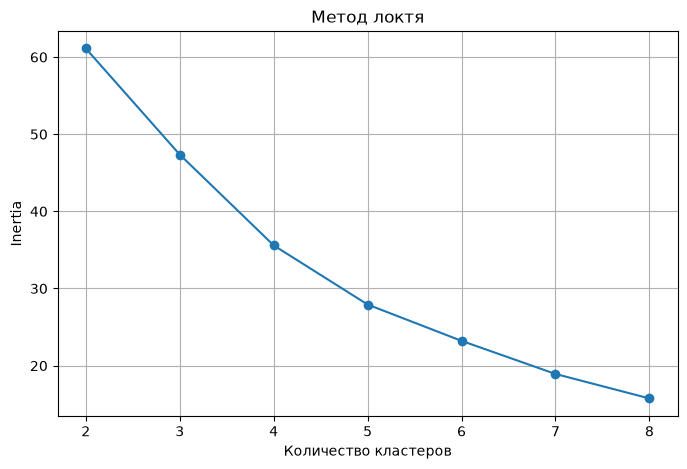

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(K, inertia, marker="o")
plt.title("Метод локтя")
plt.xlabel("Количество кластеров")
plt.ylabel("Inertia")
plt.xticks(K)
plt.grid()
plt.show()

При увеличении количества кластеров `inertia_` всегда уменьшается. Нужно найти такую точку, после которой уменьшение `inertia_` становится менее существенным - это точка называется локтем. 

В нашем случае после 4х кластеров уменьшение параметра `inertia_` становится меньше, (более плавным), поэтому здесь также можно оставить 4 кластера. *Но этот метод не гарантирует, что выбор количества кластеров окажется оптимальным, поэтому есть смысл перебирать несколько инструментов*

#### Коэффициент силуэта

Показывает, насколько хорошо каждый объект расположен внутри своего кластера относительно ближайшего соседнего кластера. То есть силуэт оценивает:

* насколько близко объект находится к объектам своего кластера
* насколько далеко он находится от объектов ближайшего другого кластера

Значение коэффициента в пределах $[-1, 1]$ и чем выше значение, тем лучше разделены кластеры по этому критерию. 

In [ ]:
silhouette = []
calinski = []
davies = []

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

    # получим предсказания
    labels = kmeans.fit_predict(df_scaled)

    # посчитаем коэффициенты
    silhouette.append(silhouette_score(df_scaled, labels))
    calinski.append(calinski_harabasz_score(df_scaled, labels))
    davies.append(davies_bouldin_score(df_scaled, labels))

Визуализируем полученные результаты

In [18]:
metrics = pd.DataFrame(
    {
        "K": list(K),
        "Silhouette": silhouette,
        "Calinski-Harabasz": calinski,
        "Davies-Bouldin": davies,
    }
)

metrics.round(3)

,K,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,0.470,55.351,0.808
1,3,0.388,41.146,0.905
2,4,0.340,40.282,1.098
3,5,0.369,40.412,0.936
4,6,0.373,39.560,0.933
5,7,0.368,40.908,0.882
6,8,0.406,42.142,0.714


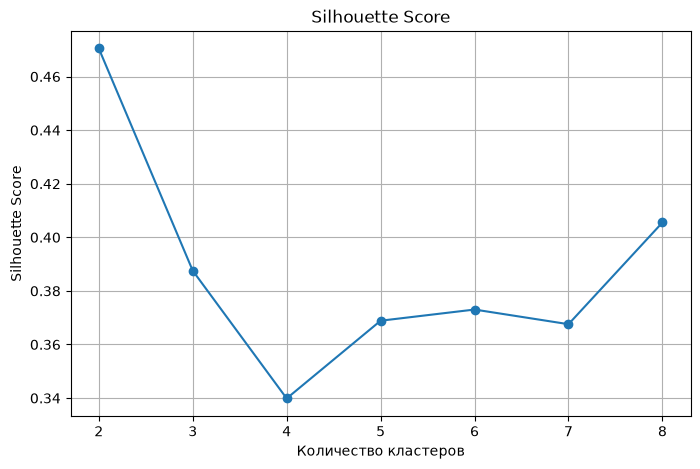

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(K, silhouette, marker="o")
plt.title("Silhouette Score")
plt.xlabel("Количество кластеров")
plt.ylabel("Silhouette Score")
plt.xticks(K)
plt.grid()
plt.show()

**Calinski-Harabasz Index**

Данная метрика оценивает отношение межкластерного разброса к внутрикластерному. Иными словами, она показывает, насколько далеко друг от друга расположены кластеры относительно того, насколько сильно разбросаны объекты внутри каждого кластера.

* высокое значение означает, что кластеры хорошо отделены друг от друга
* низкое значение говорит о менее выраженном разделении

Нам нужно, чтобы **значение было наибольшим.**

**Davies-Bouldin Index**

Метрика оценивает сходство каждого кластера с наиболее похожим на него другим кластером.

При расчёте учитываются:

* разброс объектов внутри кластеров
* расстояния между центрами кластеров

Если кластеры компактные и хорошо разделены, значение метрики будет небольшим. Нам нужно, чтобы эта **метрика была наименьшая.**

#### Вывод по метрикам

По результатам расчётов можно сделать следующие наблюдения:

1. Silhouette Score достигает максимума при K = 2 (0.470), это говорит о том, что разделение на два кластера обеспечивает наиболее выраженное разделение объектов среди рассмотренных вариантов
2. Calinski-Harabasz также достигает максимума при K = 2 (55.351), что подтверждает хорошую разделённость кластеров
3. Davies-Bouldin достигает минимума при K = 8 (0.714). Судя по этому критерию, лучше всего получается разбиение на восемь кластеров

Каждая из метрик оценивает кластеры по своему, поэтому вполне нормально, что метрики у нас отличаются. 

### Кластеризация

**Возьмем k=3 кластеров, на основе выводов в предыдущем задании**

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Обучим и сразу запишем предсказания
df["cluster"] = kmeans.fit_predict(df_scaled)

Посмотрим на средние значения признаков в каждом кластере

In [26]:
df.groupby("cluster")[["Work", "Price", "Salary"]].mean().round(2)

,Work,Price,Salary
cluster,,,
0,1855.45,50.78,16.59
1,1789.24,84.97,59.03
2,2133.50,54.17,16.08


Вспомним кратко что означают каждый из признаков:
- Work (Работа): среднее числа рабочих часов
- Price (Цена): Индекс цен 112 товаров и услуг
- Salary (Заработная плата): индекс з/п за час работы.

Отсюда видно следующее:
1. **Кластер 0** - города со средним уровнем экономического развития. Средняя продолжительность рабочего времени составляет около 1855 часов в год, индекс цен - 50.78, а индекс заработной платы - 16.59. Для этих городов характерны относительно низкие цены и невысокая оплата труда при обычной продолжительности рабочего времени.
2. **Кластер 1** - богатые города с высоким уровнем оплаты труда. Это наиболее благополучная группа: индекс цен составляет 84.97, а индекс заработной платы - 59.03. При этом средняя продолжительность рабочего времени составляет 1789 часов в год, что является минимальным значением среди трёх кластеров.
3. **Кластер 2** - города с продолжительным рабочим временем и низкой оплатой труда. Средняя продолжительность рабочего времени достигает 2133.5 часа в год - это максимальный показатель среди всех групп. При этом индекс цен составляет 54.17, а индекс заработной платы - 16.08. Таким образом, жители этих городов работают больше остальных, но получают сравнительно низкую оплату труда.

Посмотрим на то, какие города относятся к каждому из кластеров

In [27]:
for cluster_id, group in df.groupby("cluster"):
    print(f"\nКластер {cluster_id} (размер {group.shape[0]}):")
    print(group["City"].tolist())


Кластер 0 (размер 11):
['Athens', 'Buenos_Aires', 'Johannesburg', 'Lagos', 'Lisbon', 'Mexico_City', 'Nairobi', 'Nicosia', 'Rio_de_Janeiro', 'San_Paulo', 'Seoul']

Кластер 1 (размер 25):
['Amsterdam', 'Brussels', 'Chicago', 'Copenhagen', 'Dublin', 'Dusseldorf', 'Frankfurt', 'Geneva', 'Helsinki', 'Houston', 'London', 'Los_Angeles', 'Luxembourg', 'Madrid', 'Milan', 'Montreal', 'New_York', 'Oslo', 'Paris', 'Stockholm', 'Sydney', 'Tokyo', 'Toronto', 'Vienna', 'Zurich']

Кластер 2 (размер 10):
['Bogota', 'Bombay', 'Caracas', 'Hong_Kong', 'Kuala_Lumpur', 'Manila', 'Panama', 'Singpore', 'Taipei', 'Tel_Aviv']


**Визуализируем кластеры**

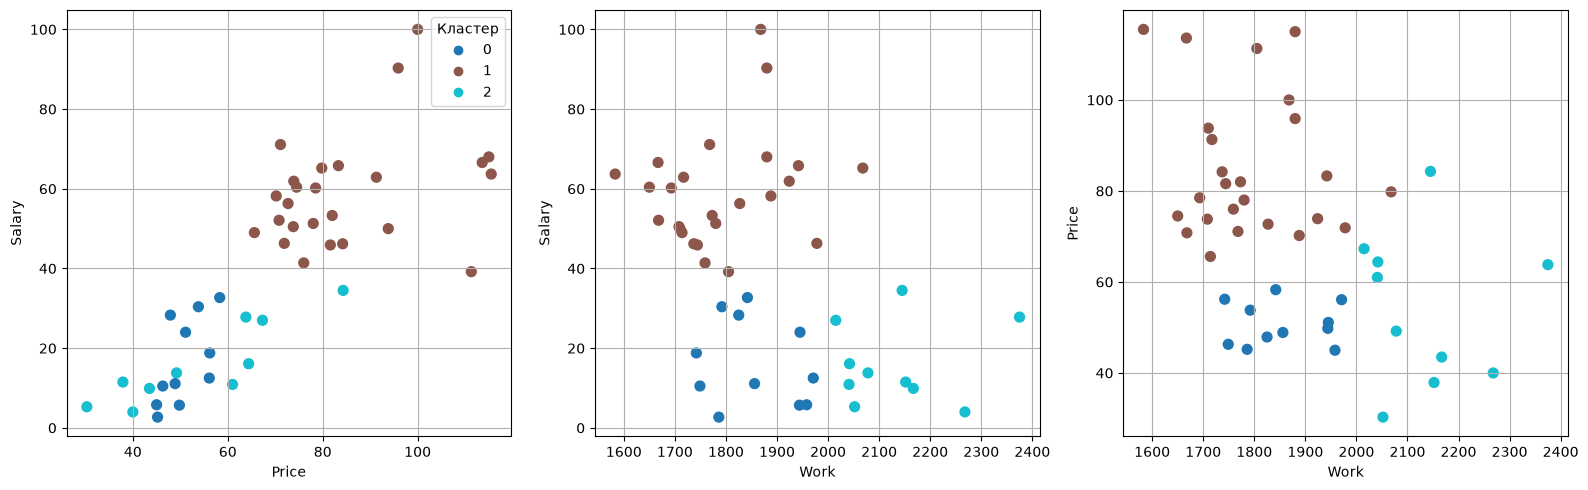

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (x, y) in zip(
    axes, [("Price", "Salary"), ("Work", "Salary"), ("Work", "Price")]
):
    sc = ax.scatter(df[x], df[y], c=df["cluster"], cmap="tab10", s=50)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.grid(True)
axes[0].legend(*sc.legend_elements(), title="Кластер")
plt.tight_layout()
plt.show()

Визуализация позволяет оценить расположение городов относительно друг друга по различным парам экономических показателей. Видно, что кластеры различаются прежде всего по уровню цен и заработной платы, а также по продолжительности рабочего времени

### Проведем сравнение с иерархическим кластерным анализом

Сравним результаты обоих методов между собой по метрике **Adjusted Rand Index (ARI)**. 

ARI оценивает сходство двух разбиений одних и тех же объектов:
* 1 - полное совпадение
* около 0 - сходство на уровне случайного разбиения
* отрицательное значение - разбиения хуже случайного ориентира

Повторим иерархическую кластеризацию

In [41]:
# Обучим иерарх. класт.
link = linkage(df_scaled, method="ward", metric="euclidean")

# Получим предсказания
labels_ward_3 = fcluster(link, 3, criterion="maxclust")

# Посчитаем и выведем метрику
ari_3 = adjusted_rand_score(df["cluster"], labels_ward_3)
print(f"ARI: {ari_3:.3f}")

ARI: 0.862


Значение ARI = 0.862 говорит о высокой степени сходства результатов кластеризации методами K-means и Ward при разбиении данных на 3 кластера. Оба метода в значительной степени относят одни и те же города к одним и тем же группам, при этом разбиения не идентичны, поскольку ARI не достигает 1

Таким образом, результаты двух методов достаточно согласованы, что подтверждает устойчивость выявленной кластерной структуры

Посмотрим, какие города оказались в разных кластерах при использовании двух алгоритмов.

In [ ]:
comparison = pd.DataFrame(
    {"City": df["City"], "K-means": df["cluster"], "Ward": labels_ward_3}
)

comparison.sort_values(["K-means", "City"])

,City,K-means,Ward
1,Athens,0,2
5,Buenos_Aires,0,3
16,Johannesburg,0,3
18,Lagos,0,2
19,Lisbon,0,2
25,Mexico_City,0,3
28,Nairobi,0,3
30,Nicosia,0,2
34,Rio_de_Janeiro,0,2
35,San_Paulo,0,2


Сравнение показывает, что алгоритмы по-разному распределяют отдельные города между группами, поскольку K-means формирует кластеры относительно центров, а иерархический метод Уорда последовательно объединяет группы объектов с учётом увеличения внутрикластерной дисперсии.

## Общий вывод

Мы провели кластерный анализ методом k-means на основе датасета **Economics of Cities**. В ходе работы были выполнены следующие действия:
1. Проведена предварительная обработка данных: удалены две записи с некорректными значениями -9999.
2. Выполнена стандартизация числовых признаков Work, Price и Salary.
3. Исследовано оптимальное количество кластеров с помощью метода локтя.
4. Рассчитаны и сравнены метрики качества кластеризации: Silhouette Score, Calinski-Harabasz и Davies-Bouldin.
5. Проведена кластеризация с использованием алгоритма K-means.
6. Проанализированы средние значения признаков и состав полученных кластеров.
7. Построены графики для визуального представления результатов.
8. Проведено сравнение с результатами иерархической кластеризации методом Уорда.

По результатам исследования было выбрано **три кластера**.

В результате удалось выделить следующие группы городов:

* Города с высоким уровнем цен и заработной платы, характеризующиеся относительно небольшой продолжительностью рабочего времени.
* Города с низкими ценами и заработной платой, имеющие обычную продолжительность рабочего времени.
* Города с низкой заработной платой и продолжительным рабочим временем.

Таким образом, применение K-means позволило выделить три группы городов с различными экономическими характеристиками.

Сравнение с иерархической кластеризацией позволяет дополнительно оценить сходство результатов двух алгоритмов и устойчивость полученного разбиения

**Итог: кластерный анализ удался!**